<a href="https://colab.research.google.com/github/Abhijeet835/Manish-General-Store/blob/main/MediAI_CS24308.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo -q
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=891)   # CDC Diabetes Health Indicators
X = data.data.features
y = data.data.targets['Diabetes_binary']

print("Patients and features:", X.shape)
print(y.value_counts())

Patients and features: (253680, 21)
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64


In [ ]:
print(X.head())
print("Missing values:", X.isnull().sum().sum())
print("Diabetic share: %.1f%%" % (y.mean() * 100))

   HighBP  HighChol  CholCheck  BMI  Smoker  Stroke  HeartDiseaseorAttack  \
0       1         1          1   40       1       0                     0   
1       0         0          0   25       1       0                     0   
2       1         1          1   28       0       0                     0   
3       1         0          1   27       0       0                     0   
4       1         1          1   24       0       0                     0   

   PhysActivity  Fruits  Veggies  ...  AnyHealthcare  NoDocbcCost  GenHlth  \
0             0       0        1  ...              1            0        5   
1             1       0        0  ...              0            1        3   
2             0       1        0  ...              1            1        5   
3             1       1        1  ...              1            0        2   
4             1       1        1  ...              1            0        2   

   MentHlth  PhysHlth  DiffWalk  Sex  Age  Education  Income  
0    

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 80% to learn from, 20% locked away for honest testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Balance ONLY the training set: keep all diabetics, sample equal non-diabetics
train = X_train.copy()
train['y'] = y_train.values
pos = train[train.y == 1]
neg = train[train.y == 0].sample(len(pos), random_state=42)
bal = pd.concat([pos, neg]).sample(frac=1, random_state=42)
Xb = bal.drop(columns='y')
yb = bal['y']

# Scale features so the network trains well
scaler = StandardScaler().fit(Xb)
Xb_s = scaler.transform(Xb)
X_test_s = scaler.transform(X_test)

print("Training rows after balancing:", len(Xb))
print("Test rows:", len(X_test))

Training rows after balancing: 56554
Test rows: 50736


Accuracy: 0.708
AUC: 0.824
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     43667
           1       0.30      0.81      0.44      7069

    accuracy                           0.71     50736
   macro avg       0.63      0.75      0.62     50736
weighted avg       0.87      0.71      0.75     50736



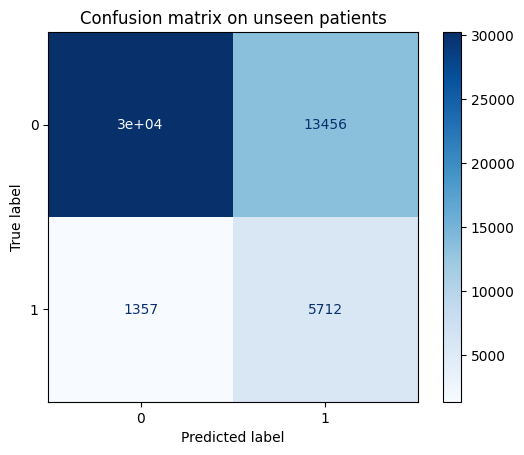

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model = MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                      max_iter=200, random_state=42)
model.fit(Xb_s, yb)

pred = model.predict(X_test_s)
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("AUC:", round(roc_auc_score(y_test, model.predict_proba(X_test_s)[:, 1]), 3))
print(classification_report(y_test, pred))

ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues')
plt.title("Confusion matrix on unseen patients")
plt.show()

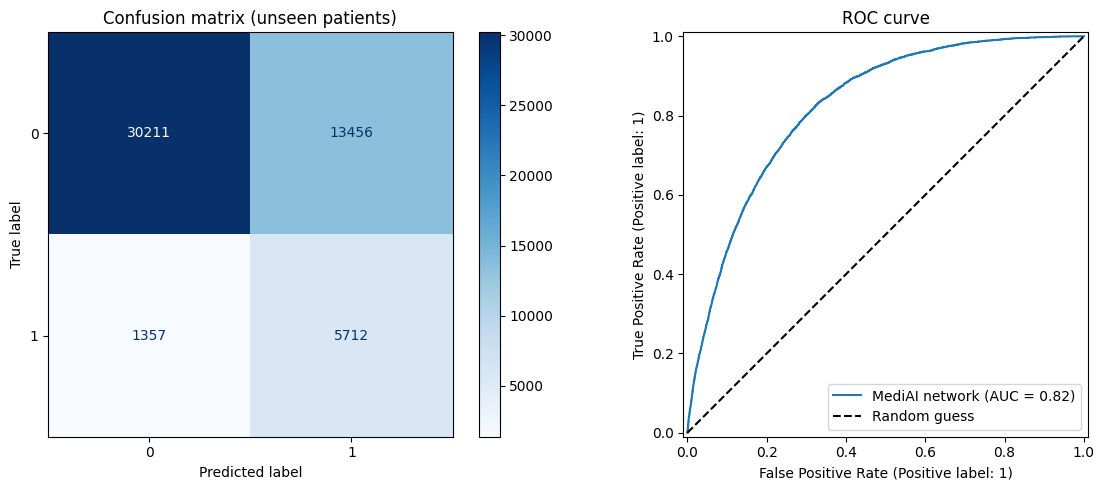

In [ ]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues',
                                        values_format='d', ax=ax[0])
ax[0].set_title("Confusion matrix (unseen patients)")

RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test_s)[:, 1],
                                 ax=ax[1], name="MediAI network")
ax[1].plot([0, 1], [0, 1], 'k--', label="Random guess")
ax[1].legend()
ax[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

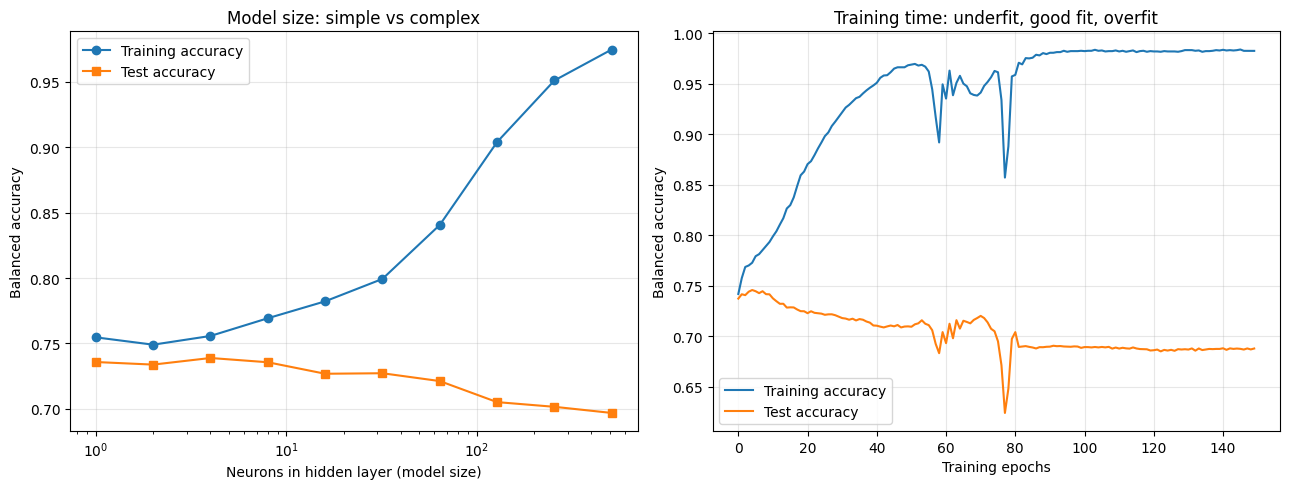

Final gap (big network): train 0.98 vs test 0.69


In [ ]:
import numpy as np, warnings
from sklearn.metrics import balanced_accuracy_score
warnings.filterwarnings("ignore")

rng = np.random.RandomState(42)
small = rng.choice(len(Xb_s), 3000, replace=False)
Xs, ys = Xb_s[small], yb.values[small]
test_idx = rng.choice(len(X_test_s), 10000, replace=False)
Xt, yt = X_test_s[test_idx], y_test.values[test_idx]

# A) effect of model size
sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
tr_a, te_a = [], []
for s in sizes:
    m = MLPClassifier(hidden_layer_sizes=(s,), alpha=0.0, max_iter=300, random_state=42)
    m.fit(Xs, ys)
    tr_a.append(balanced_accuracy_score(ys, m.predict(Xs)))
    te_a.append(balanced_accuracy_score(yt, m.predict(Xt)))

# B) effect of training time (epochs) for a big network
big = MLPClassifier(hidden_layer_sizes=(256, 256), alpha=0.0, random_state=42)
tr_b, te_b = [], []
for epoch in range(150):
    big.partial_fit(Xs, ys, classes=[0, 1])
    tr_b.append(balanced_accuracy_score(ys, big.predict(Xs)))
    te_b.append(balanced_accuracy_score(yt, big.predict(Xt)))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(sizes, tr_a, 'o-', label="Training accuracy")
ax[0].plot(sizes, te_a, 's-', label="Test accuracy")
ax[0].set_xscale('log')
ax[0].set_xlabel("Neurons in hidden layer (model size)")
ax[0].set_ylabel("Balanced accuracy")
ax[0].set_title("Model size: simple vs complex")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(tr_b, label="Training accuracy")
ax[1].plot(te_b, label="Test accuracy")
ax[1].set_xlabel("Training epochs")
ax[1].set_ylabel("Balanced accuracy")
ax[1].set_title("Training time: underfit, good fit, overfit")
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Final gap (big network): train %.2f vs test %.2f" % (tr_b[-1], te_b[-1]))

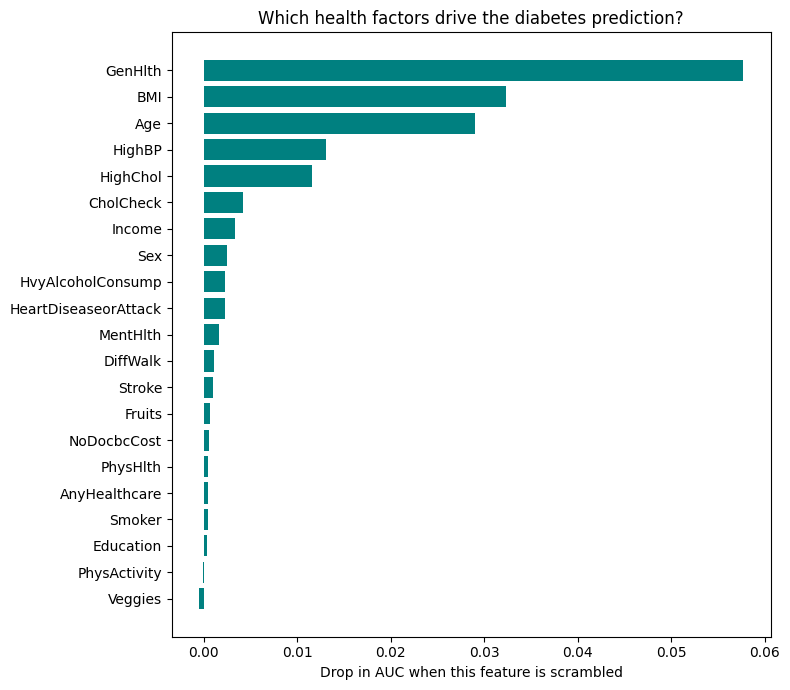

In [ ]:
from sklearn.inspection import permutation_importance

idx = np.random.RandomState(42).choice(len(X_test_s), 10000, replace=False)
r = permutation_importance(model, X_test_s[idx], y_test.values[idx],
                           scoring='roc_auc', n_repeats=3, random_state=42)
order = r.importances_mean.argsort()

plt.figure(figsize=(8, 7))
plt.barh(np.array(X.columns)[order], r.importances_mean[order], color='teal')
plt.xlabel("Drop in AUC when this feature is scrambled")
plt.title("Which health factors drive the diabetes prediction?")
plt.tight_layout()
plt.show()

In [ ]:
import joblib, sklearn, sys, os

joblib.dump({"model": model, "scaler": scaler,
             "features": list(X.columns), "base_rate": float(y.mean())},
            "mediai_model.joblib", compress=3)

print("Features:", list(X.columns))
print("scikit-learn:", sklearn.__version__)
print("Python:", sys.version.split()[0])
print("Model file size (KB):", round(os.path.getsize("mediai_model.joblib") / 1024))

Features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
scikit-learn: 1.6.1
Python: 3.13.18
Model file size (KB): 85


In [ ]:
reqs = "streamlit\nscikit-learn==" + sklearn.__version__ + "\nnumpy\npandas\njoblib\nmatplotlib\n"
open("requirements.txt", "w").write(reqs)
print(reqs)

streamlit
scikit-learn==1.6.1
numpy
pandas
joblib
matplotlib



In [ ]:
%%writefile app.py
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="MediAI", page_icon="🩺", layout="wide")

@st.cache_resource
def load_bundle():
    return joblib.load("mediai_model.joblib")

bundle = load_bundle()
model = bundle["model"]
scaler = bundle["scaler"]
features = bundle["features"]
base_rate = bundle["base_rate"]

AGE = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
       "55-59", "60-64", "65-69", "70-74", "75-79", "80 or older"]
HEALTH = ["1 - Excellent", "2 - Very good", "3 - Good", "4 - Fair", "5 - Poor"]
EDU = ["Never attended / kindergarten", "Grades 1-8", "Grades 9-11",
       "Grade 12 / GED", "College 1-3 years", "College 4+ years"]
INCOME = ["Below 10k", "10k-15k", "15k-20k", "20k-25k",
          "25k-35k", "35k-50k", "50k-75k", "75k or more"]

st.title("🩺 MediAI: Diabetes Risk Screening Assistant")
st.caption("CS24308 Artificial Intelligence Lab | Educational project, not medical advice")

tab1, tab2, tab3 = st.tabs(["Risk checker", "Model performance", "About the team"])

# ---------------- TAB 1: risk checker ----------------
with tab1:
    c1, c2, c3 = st.columns(3)
    with c1:
        st.subheader("Basic details")
        age = st.selectbox("Age group", AGE, index=6)
        sex = st.radio("Sex", ["Female", "Male"], horizontal=True)
        height = st.number_input("Height (cm)", 120, 220, 168)
        weight = st.number_input("Weight (kg)", 30, 250, 70)
        bmi = weight / ((height / 100) ** 2)
        st.write("Calculated BMI: **%.1f**" % bmi)
        genhlth = st.selectbox("General health", HEALTH, index=2)
        edu = st.selectbox("Education level", EDU, index=3)
        income = st.selectbox("Yearly income band (US dollars, as in the survey)", INCOME, index=4)
    with c2:
        st.subheader("Medical history")
        highbp = st.checkbox("High blood pressure")
        highchol = st.checkbox("High cholesterol")
        cholcheck = st.checkbox("Cholesterol checked in last 5 years", value=True)
        stroke = st.checkbox("Ever had a stroke")
        heart = st.checkbox("Heart disease or heart attack")
        diffwalk = st.checkbox("Serious difficulty walking or climbing stairs")
        ment = st.slider("Days of poor mental health (last 30)", 0, 30, 0)
        phys = st.slider("Days of poor physical health (last 30)", 0, 30, 0)
    with c3:
        st.subheader("Lifestyle and access")
        smoker = st.checkbox("Smoked 100+ cigarettes in lifetime")
        physact = st.checkbox("Physical activity in last 30 days", value=True)
        fruits = st.checkbox("Eats fruit daily", value=True)
        veggies = st.checkbox("Eats vegetables daily", value=True)
        alcohol = st.checkbox("Heavy alcohol consumption")
        healthcare = st.checkbox("Has health coverage", value=True)
        nodoc = st.checkbox("Could not see a doctor due to cost")

    vals = {
        "HighBP": int(highbp), "HighChol": int(highchol), "CholCheck": int(cholcheck),
        "BMI": bmi, "Smoker": int(smoker), "Stroke": int(stroke),
        "HeartDiseaseorAttack": int(heart), "PhysActivity": int(physact),
        "Fruits": int(fruits), "Veggies": int(veggies),
        "HvyAlcoholConsump": int(alcohol), "AnyHealthcare": int(healthcare),
        "NoDocbcCost": int(nodoc), "GenHlth": HEALTH.index(genhlth) + 1,
        "MentHlth": ment, "PhysHlth": phys, "DiffWalk": int(diffwalk),
        "Sex": 1 if sex == "Male" else 0, "Age": AGE.index(age) + 1,
        "Education": EDU.index(edu) + 1, "Income": INCOME.index(income) + 1,
    }

    if st.button("Check my risk", type="primary"):
        missing = [f for f in features if f not in vals]
        if missing:
            st.error("Feature names do not match the model: " + ", ".join(missing))
            st.stop()

        row = pd.DataFrame([vals])[features]
        p_model = model.predict_proba(scaler.transform(row))[0, 1]
        # Bayes correction: the model was trained on 50/50 data, reality is ~14% diabetic
        p_real = (p_model * base_rate) / (p_model * base_rate + (1 - p_model) * (1 - base_rate))

        m1, m2, m3 = st.columns(3)
        m1.metric("Raw model score", "%.0f%%" % (p_model * 100))
        m2.metric("Estimated real-world risk", "%.0f%%" % (p_real * 100))
        m3.metric("Population average", "%.1f%%" % (base_rate * 100))

        if p_real < base_rate:
            st.success("Below the population average. The model would not flag this person.")
        elif p_real < 0.30:
            st.warning("Above average. A blood sugar test (fasting glucose or HbA1c) is advisable.")
        else:
            st.error("High risk. Please consult a doctor and get tested soon.")

        fig, ax = plt.subplots(figsize=(6, 1.8))
        ax.barh(["Average person", "This patient"], [base_rate * 100, p_real * 100],
                color=["grey", "crimson" if p_real >= 0.30 else "teal"])
        ax.set_xlim(0, 100)
        ax.set_xlabel("Estimated diabetes risk (%)")
        st.pyplot(fig)

        with st.expander("How is this calculated?"):
            st.write(
                "A neural network (2 hidden layers: 64 and 32 neurons) was trained on 253,680 "
                "real survey records from the CDC BRFSS 2015 survey. It was trained on a balanced "
                "50/50 sample, so its raw score overestimates real risk. We apply Bayes' theorem "
                "with the real prior (%.1f%% of people are diabetic) to correct it. "
                "This is a screening aid for learning purposes, not a diagnosis." % (base_rate * 100))

# ---------------- TAB 2: performance ----------------
with tab2:
    st.subheader("Results on 50,736 unseen patients")
    a, b, c, d = st.columns(4)
    a.metric("AUC", "0.824")
    b.metric("Accuracy", "70.8%")
    c.metric("Recall (diabetic)", "81%")
    d.metric("Precision (diabetic)", "30%")
    st.write("Of 7,069 diabetic patients in the test set, the model caught **5,712** and missed **1,357**. "
             "For a screening tool, missing fewer sick patients matters more than avoiding false alarms.")
    cm = pd.DataFrame([[30211, 13456], [1357, 5712]],
                      index=["Actually healthy", "Actually diabetic"],
                      columns=["Predicted healthy", "Predicted diabetic"])
    st.table(cm)

# ---------------- TAB 3: team ----------------
with tab3:
    st.subheader("Project team")
    st.table(pd.DataFrame({
        "Name": ["Abhijeet Gorai", "Nilesh Kumar", "Yash Raj"],
        "Roll number": ["BTECH/10024/24", "BTECH/10054/24", "BTECH/10047/24"],
    }))
    st.write("**Program:** B.Tech CSE")
    st.write("**Subject:** CS24308 Artificial Intelligence Lab | **Session:** MO-26")
    st.write("**Submitted to:** Dr. Satish Chander")
    st.write("**Dataset:** CDC Diabetes Health Indicators (UCI repository, 253,680 patients)")

Writing app.py


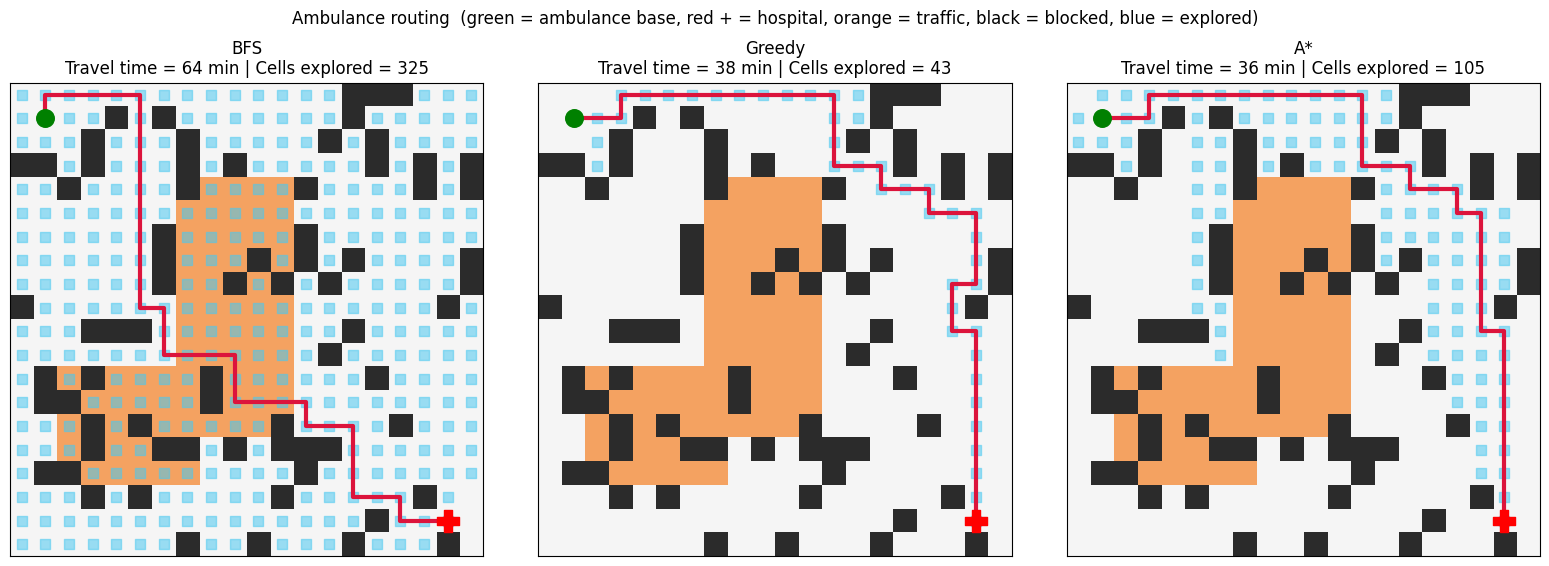

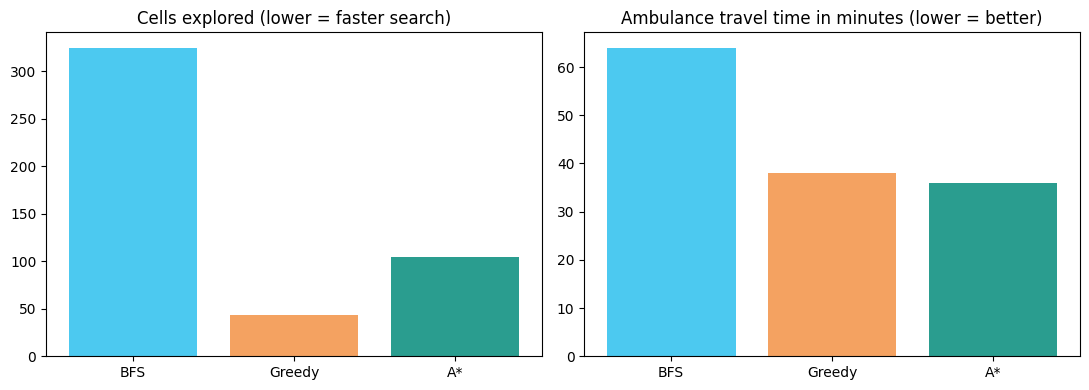

BFS     travel time =  64 min | cells explored = 325
Greedy  travel time =  38 min | cells explored =  43
A*      travel time =  36 min | cells explored = 105


In [ ]:
import heapq
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

N = 20
START, GOAL = (1, 1), (18, 18)       # ambulance base, hospital

def neighbors(city, p):
    r, c = p
    for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < N and 0 <= nc < N and city[nr, nc] != 0:
            yield (nr, nc)

def make_city():
    # try different random layouts until the hospital is reachable
    for seed in range(100):
        rng = np.random.RandomState(seed)
        city = np.ones((N, N), dtype=int)           # 1 = clear road (cost 1)
        city[rng.rand(N, N) < 0.18] = 0             # 0 = blocked (building / flooded road)
        for (r0, r1, c0, c1) in [(4, 15, 7, 12), (12, 17, 2, 8)]:
            patch = city[r0:r1, c0:c1]
            patch[patch == 1] = 5                   # 5 = heavy traffic (cost 5)
        city[START] = 1
        city[GOAL] = 1
        path, _ = bfs(city, START, GOAL)
        if path:
            return city
    raise RuntimeError("no map found")

def rebuild(came, g):
    if g not in came:
        return None
    path, cur = [], g
    while cur is not None:
        path.append(cur)
        cur = came[cur]
    return path[::-1]

def manhattan(p, g):
    return abs(p[0] - g[0]) + abs(p[1] - g[1])

def bfs(city, s, g):
    q, came, explored = deque([s]), {s: None}, []
    while q:
        cur = q.popleft()
        explored.append(cur)
        if cur == g:
            break
        for nb in neighbors(city, cur):
            if nb not in came:
                came[nb] = cur
                q.append(nb)
    return rebuild(came, g), explored

def greedy(city, s, g):
    pq, came, explored, seen = [(manhattan(s, g), s)], {s: None}, [], {s}
    while pq:
        _, cur = heapq.heappop(pq)
        explored.append(cur)
        if cur == g:
            break
        for nb in neighbors(city, cur):
            if nb not in seen:
                seen.add(nb)
                came[nb] = cur
                heapq.heappush(pq, (manhattan(nb, g), nb))
    return rebuild(came, g), explored

def astar(city, s, g):
    pq, came, cost, explored = [(manhattan(s, g), s)], {s: None}, {s: 0}, []
    done = set()
    while pq:
        _, cur = heapq.heappop(pq)
        if cur in done:
            continue
        done.add(cur)
        explored.append(cur)
        if cur == g:
            break
        for nb in neighbors(city, cur):
            new = cost[cur] + city[nb]
            if nb not in cost or new < cost[nb]:
                cost[nb] = new
                came[nb] = cur
                heapq.heappush(pq, (new + manhattan(nb, g), nb))
    return rebuild(came, g), explored

def travel_time(city, path):
    return int(sum(city[r, c] for r, c in path[1:]))

city = make_city()
results = {}
for name, fn in [("BFS", bfs), ("Greedy", greedy), ("A*", astar)]:
    path, explored = fn(city, START, GOAL)
    results[name] = (path, explored, travel_time(city, path))

shade = ListedColormap(["#2b2b2b", "#f5f5f5", "#f4a261"])
idx = np.select([city == 0, city == 1, city == 5], [0, 1, 2])
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (name, (path, explored, t)) in zip(axes, results.items()):
    ax.imshow(idx, cmap=shade, vmin=0, vmax=2)
    ex = np.array(explored)
    ax.scatter(ex[:, 1], ex[:, 0], s=45, c="#4cc9f0", alpha=0.55, marker="s")
    p = np.array(path)
    ax.plot(p[:, 1], p[:, 0], color="crimson", lw=3)
    ax.scatter(*START[::-1], s=160, c="green", marker="o", zorder=5)
    ax.scatter(*GOAL[::-1], s=260, c="red", marker="P", zorder=5)
    ax.set_title("%s\nTravel time = %d min | Cells explored = %d" % (name, t, len(explored)))
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Ambulance routing  (green = ambulance base, red + = hospital, orange = traffic, black = blocked, blue = explored)", y=1.02)
plt.tight_layout()
plt.show()

names = list(results)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(names, [len(results[n][1]) for n in names], color=["#4cc9f0", "#f4a261", "#2a9d8f"])
ax[0].set_title("Cells explored (lower = faster search)")
ax[1].bar(names, [results[n][2] for n in names], color=["#4cc9f0", "#f4a261", "#2a9d8f"])
ax[1].set_title("Ambulance travel time in minutes (lower = better)")
plt.tight_layout()
plt.show()
for n in names:
    print("%-7s travel time = %3d min | cells explored = %3d" % (n, results[n][2], len(results[n][1])))

Patient A (58 yr man)
Known facts : ['age_over_50', 'chest_pain', 'high_bp', 'sweating']
  R1   IF chest_pain AND sweating                       THEN suspect_heart_attack
  R2   IF age_over_50 AND suspect_heart_attack          THEN cardiac_emergency
  R13  IF cardiac_emergency                             THEN CRITICAL
TRIAGE -> RED   (call ambulance now)
Patient B (35 yr woman)
Known facts : ['frequent_urination', 'high_bp', 'high_glucose', 'thirst']
  R7   IF frequent_urination AND high_glucose AND thirst THEN suspect_diabetes
  R8   IF high_bp AND suspect_diabetes                  THEN needs_urgent_checkup
  R16  IF needs_urgent_checkup                          THEN URGENT
TRIAGE -> ORANGE (see doctor today)
Patient C (22 yr student)
Known facts : ['cough', 'fever', 'joint_pain', 'rash']
  R9   IF fever AND joint_pain AND rash                 THEN suspect_dengue
  R10  IF suspect_dengue                                THEN needs_urgent_checkup
  R16  IF needs_urgent_checkup           

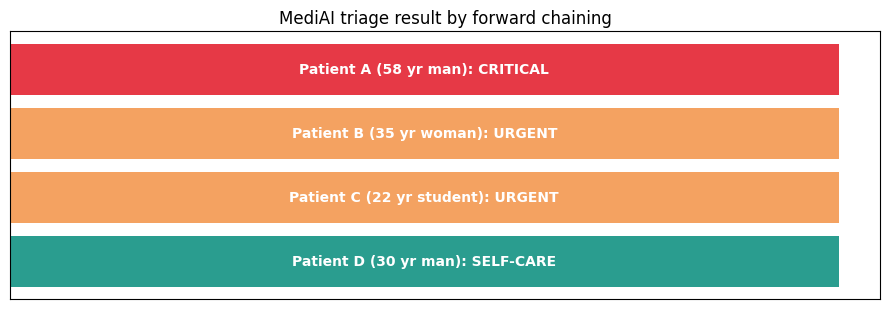

In [ ]:
RULES = [
    # (rule id, IF all of these facts..., THEN add this fact)
    ("R1",  {"chest_pain", "sweating"},                        "suspect_heart_attack"),
    ("R2",  {"suspect_heart_attack", "age_over_50"},           "cardiac_emergency"),
    ("R3",  {"face_droop", "slurred_speech"},                  "suspect_stroke"),
    ("R4",  {"suspect_stroke"},                                "neuro_emergency"),
    ("R5",  {"fever", "cough", "breathless"},                  "suspect_pneumonia"),
    ("R6",  {"suspect_pneumonia", "low_oxygen"},               "respiratory_emergency"),
    ("R7",  {"high_glucose", "thirst", "frequent_urination"},  "suspect_diabetes"),
    ("R8",  {"suspect_diabetes", "high_bp"},                   "needs_urgent_checkup"),
    ("R9",  {"fever", "rash", "joint_pain"},                   "suspect_dengue"),
    ("R10", {"suspect_dengue"},                                "needs_urgent_checkup"),
    ("R11", {"fever", "chills"},                               "suspect_malaria"),
    ("R12", {"suspect_malaria"},                               "needs_urgent_checkup"),
    ("R13", {"cardiac_emergency"},                             "CRITICAL"),
    ("R14", {"neuro_emergency"},                               "CRITICAL"),
    ("R15", {"respiratory_emergency"},                         "CRITICAL"),
    ("R16", {"needs_urgent_checkup"},                          "URGENT"),
    ("R17", {"fever"},                                         "ROUTINE"),
]

def vitals_to_facts(temp_c=None, spo2=None, systolic=None, glucose=None):
    """Convert measured numbers into symbolic facts."""
    f = set()
    if temp_c is not None and temp_c >= 38.0:    f.add("fever")
    if spo2 is not None and spo2 < 92:           f.add("low_oxygen")
    if systolic is not None and systolic >= 140: f.add("high_bp")
    if glucose is not None and glucose >= 200:   f.add("high_glucose")
    return f

def forward_chain(facts):
    facts = set(facts)
    trace = []
    changed = True
    while changed:                      # keep going until no rule adds anything new
        changed = False
        for rid, conditions, conclusion in RULES:
            if conditions <= facts and conclusion not in facts:
                facts.add(conclusion)
                trace.append((rid, sorted(conditions), conclusion))
                changed = True
    level = "CRITICAL" if "CRITICAL" in facts else "URGENT" if "URGENT" in facts \
            else "ROUTINE" if "ROUTINE" in facts else "SELF-CARE"
    return facts, trace, level

ICON = {"CRITICAL": "RED   (call ambulance now)", "URGENT": "ORANGE (see doctor today)",
        "ROUTINE": "YELLOW (clinic visit)", "SELF-CARE": "GREEN (rest, monitor)"}

patients = {
    "Patient A (58 yr man)": {"chest_pain", "sweating", "age_over_50"} | vitals_to_facts(systolic=165),
    "Patient B (35 yr woman)": {"thirst", "frequent_urination"} | vitals_to_facts(glucose=260, systolic=150),
    "Patient C (22 yr student)": {"cough", "rash", "joint_pain"} | vitals_to_facts(temp_c=39.2),
    "Patient D (30 yr man)": {"headache"} | vitals_to_facts(temp_c=36.8, spo2=98),
}

import matplotlib.pyplot as plt
colors = {"CRITICAL": "#e63946", "URGENT": "#f4a261", "ROUTINE": "#e9c46a", "SELF-CARE": "#2a9d8f"}
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (name, facts) in enumerate(patients.items()):
    final, trace, level = forward_chain(facts)
    print("=" * 70)
    print(name)
    print("Known facts :", sorted(facts))
    for rid, cond, concl in trace:
        print("  %-4s IF %-45s THEN %s" % (rid, " AND ".join(cond), concl))
    print("TRIAGE ->", ICON[level])
    ax.barh(i, 1, color=colors[level])
    ax.text(0.5, i, "%s: %s" % (name, level), ha="center", va="center", color="white", fontweight="bold")
ax.set_yticks([]); ax.set_xticks([]); ax.invert_yaxis()
ax.set_title("MediAI triage result by forward chaining")
plt.tight_layout(); plt.show()

Prior P(diabetic) from 253,680 real patients = 0.139
                        P(E|diabetic)  P(E|healthy)  Likelihood ratio
Evidence                                                             
High blood pressure             0.753         0.377             1.999
High cholesterol                0.670         0.384             1.744
BMI 30 or more (obese)          0.582         0.308             1.887
Age 60 or older                 0.680         0.450             1.511
Poor general health             0.406         0.134             3.031
Difficulty walking              0.371         0.135             2.742

Step-by-step belief update:
  High blood pressure        present  -> P(diabetic) = 24.4%
  BMI 30 or more (obese)     present  -> P(diabetic) = 37.9%
  Age 60 or older            present  -> P(diabetic) = 48.0%
  Poor general health        present  -> P(diabetic) = 73.7%
  Difficulty walking         absent   -> P(diabetic) = 67.0%


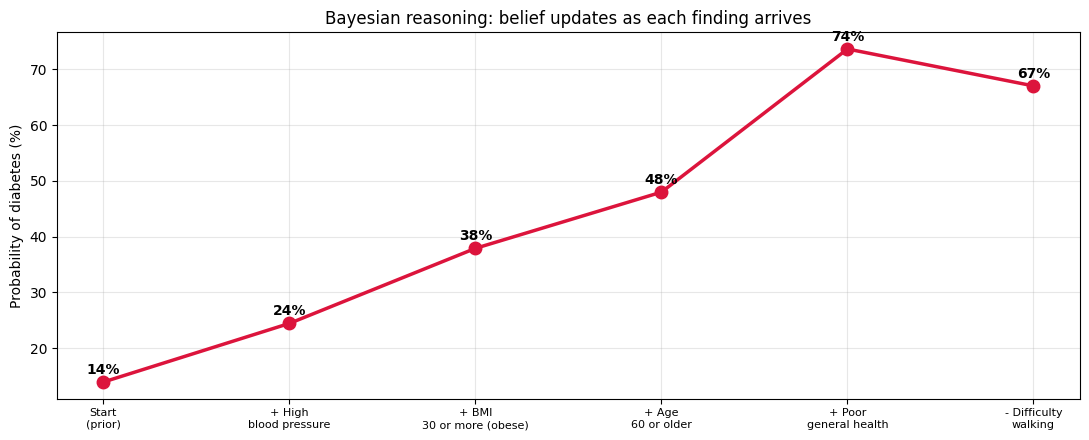

Goal stack trace:
  need 'under_treatment' -> push action 'Start treatment' and its preconditions
  need 'stabilized' -> push action 'Stabilize patient' and its preconditions
  need 'at_hospital' -> push action 'Transport to hospital' and its preconditions
  need 'ambulance_at_patient' -> push action 'Route ambulance (A*)' and its preconditions
  need 'ambulance_called' -> push action 'Call ambulance' and its preconditions
  need 'triaged' -> push action 'Triage patient' and its preconditions
  need 'tests_done' -> push action 'Run blood tests' and its preconditions

FINAL RESCUE-AND-TREATMENT PLAN
  1. Triage patient
  2. Call ambulance
  3. Route ambulance (A*)
  4. Transport to hospital
  5. Stabilize patient
  6. Run blood tests
  7. Start treatment


In [ ]:
# ---------- (a) Bayesian updating using REAL data from the dataset ----------
import pandas as pd
import matplotlib.pyplot as plt

evidence = {
    "High blood pressure":       X["HighBP"] == 1,
    "High cholesterol":          X["HighChol"] == 1,
    "BMI 30 or more (obese)":    X["BMI"] >= 30,
    "Age 60 or older":           X["Age"] >= 9,
    "Poor general health":       X["GenHlth"] >= 4,
    "Difficulty walking":        X["DiffWalk"] == 1,
}

prior = float(y.mean())
rows = []
for name, mask in evidence.items():
    p_given_diabetic = float(mask[y == 1].mean())    # P(evidence | diabetic)
    p_given_healthy  = float(mask[y == 0].mean())    # P(evidence | not diabetic)
    rows.append((name, p_given_diabetic, p_given_healthy))
lik = pd.DataFrame(rows, columns=["Evidence", "P(E|diabetic)", "P(E|healthy)"]).set_index("Evidence")
lik["Likelihood ratio"] = lik["P(E|diabetic)"] / lik["P(E|healthy)"]
print("Prior P(diabetic) from 253,680 real patients = %.3f" % prior)
print(lik.round(3))

def bayes_update(p, p_e_d, p_e_h, present=True):
    """Bayes' theorem: P(D|E) = P(E|D)P(D) / [P(E|D)P(D) + P(E|H)P(H)]"""
    if not present:
        p_e_d, p_e_h = 1 - p_e_d, 1 - p_e_h
    return p_e_d * p / (p_e_d * p + p_e_h * (1 - p))

patient = [("High blood pressure", True), ("BMI 30 or more (obese)", True),
           ("Age 60 or older", True), ("Poor general health", True),
           ("Difficulty walking", False)]

p = prior
steps, labels = [p], ["Start\n(prior)"]
print("\nStep-by-step belief update:")
for name, present in patient:
    p = bayes_update(p, lik.loc[name, "P(E|diabetic)"], lik.loc[name, "P(E|healthy)"], present)
    steps.append(p)
    labels.append(("+ " if present else "- ") + name.replace(" ", "\n", 1))
    print("  %-26s %-8s -> P(diabetic) = %.1f%%" % (name, "present" if present else "absent", p * 100))

plt.figure(figsize=(11, 4.5))
plt.plot(range(len(steps)), [s * 100 for s in steps], "o-", color="crimson", lw=2.5, ms=9)
for i, s in enumerate(steps):
    plt.text(i, s * 100 + 1.5, "%.0f%%" % (s * 100), ha="center", fontweight="bold")
plt.xticks(range(len(steps)), labels, fontsize=8)
plt.ylabel("Probability of diabetes (%)")
plt.title("Bayesian reasoning: belief updates as each finding arrives")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------- (b) Goal-stack planning ----------
OPS = {
    "Triage patient":          {"pre": [],                           "add": ["triaged"]},
    "Call ambulance":          {"pre": ["triaged"],                  "add": ["ambulance_called"]},
    "Route ambulance (A*)":    {"pre": ["ambulance_called"],         "add": ["ambulance_at_patient"]},
    "Transport to hospital":   {"pre": ["ambulance_at_patient"],     "add": ["at_hospital"]},
    "Stabilize patient":       {"pre": ["at_hospital"],              "add": ["stabilized"]},
    "Run blood tests":         {"pre": ["at_hospital"],              "add": ["tests_done"]},
    "Start treatment":         {"pre": ["stabilized", "tests_done"], "add": ["under_treatment"]},
}

def achiever(goal):
    for name, op in OPS.items():
        if goal in op["add"]:
            return name
    raise ValueError("No operator achieves " + goal)

def goal_stack_plan(goal, state):
    state, plan = set(state), []
    stack = [("goal", goal)]
    print("Goal stack trace:")
    while stack:
        kind, item = stack.pop()
        if kind == "goal":
            if item in state:
                continue
            op = achiever(item)
            print("  need '%s' -> push action '%s' and its preconditions" % (item, op))
            stack.append(("op", op))
            for pre in reversed(OPS[op]["pre"]):
                stack.append(("goal", pre))
        else:
            state.update(OPS[item]["add"])
            plan.append(item)
    return plan

plan = goal_stack_plan("under_treatment", set())
print("\nFINAL RESCUE-AND-TREATMENT PLAN")
for i, step in enumerate(plan, 1):
    print("  %d. %s" % (i, step))

MEDIAI MISSION REPORT: Patient A, 58-year-old man

[1] TRIAGE by forward chaining (Module III)
    R1   chest_pain + sweating  =>  suspect_heart_attack
    R2   age_over_50 + suspect_heart_attack  =>  cardiac_emergency
    R13  cardiac_emergency  =>  CRITICAL
    RESULT: RED   (call ambulance now)

[2] DIABETES RISK by neural network (Module V): 34%   (average person: 14%)
[3] DIABETES RISK by Bayes' theorem (Module IV):  58%

[4] AMBULANCE ROUTE by A* (Module II): 36 minutes to hospital (plain BFS would take 64 minutes, saving 28)

[5] ACTION PLAN by goal-stack planning (Module IV)
    1. Triage patient
    2. Call ambulance
    3. Route ambulance (A*)
    4. Transport to hospital
    5. Stabilize patient
    6. Run blood tests
    7. Start treatment


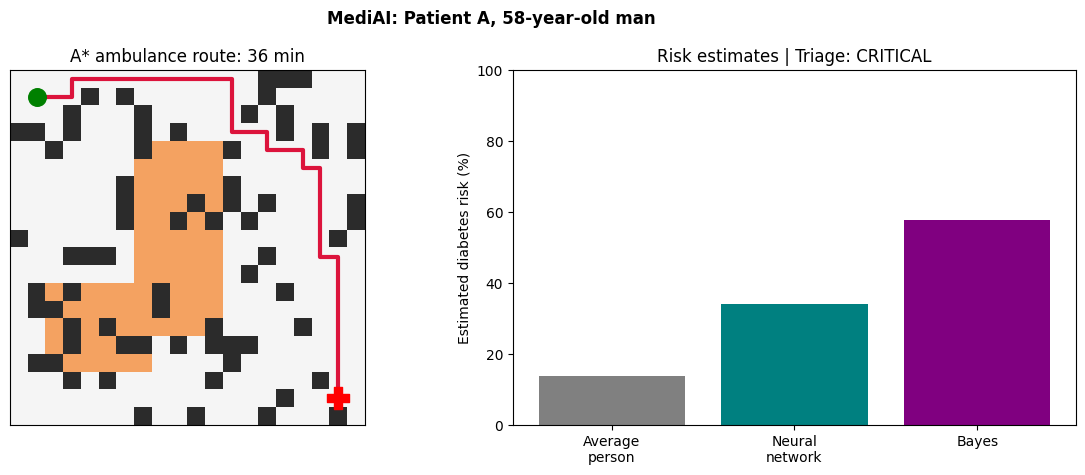

MEDIAI MISSION REPORT: Patient D, 37-year-old man

[1] TRIAGE by forward chaining (Module III)
    RESULT: GREEN (rest, monitor)

[2] DIABETES RISK by neural network (Module V): 1%   (average person: 14%)
[3] DIABETES RISK by Bayes' theorem (Module IV):  1%

[4] No ambulance needed. Advice: GREEN (rest, monitor)


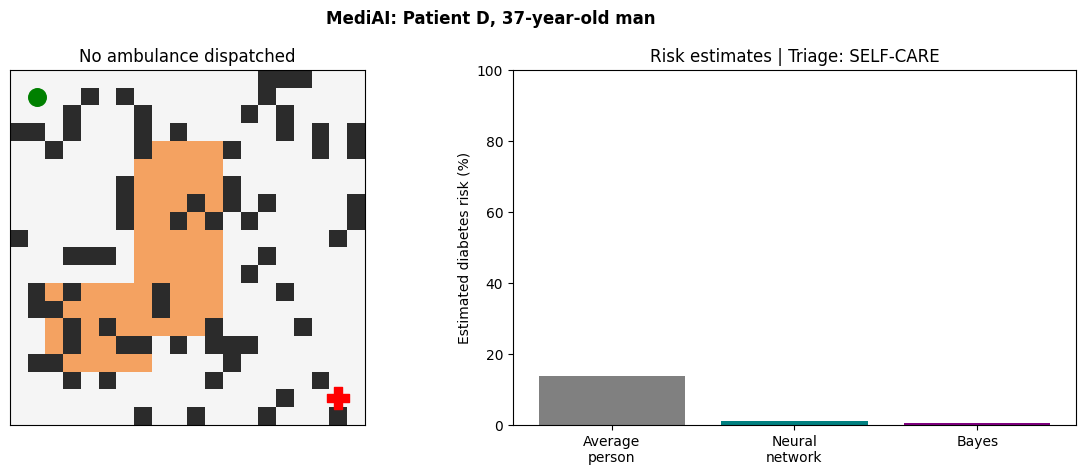

In [ ]:
# ===== FINAL DEMO: one patient through ALL five modules =====
import io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

HEALTHY = dict(HighBP=0, HighChol=0, CholCheck=1, BMI=23.0, Smoker=0, Stroke=0,
               HeartDiseaseorAttack=0, PhysActivity=1, Fruits=1, Veggies=1,
               HvyAlcoholConsump=0, AnyHealthcare=1, NoDocbcCost=0, GenHlth=2,
               MentHlth=0, PhysHlth=0, DiffWalk=0, Sex=1, Age=5, Education=5, Income=6)

def make_features(**changes):
    d = dict(HEALTHY)
    d.update(changes)
    return d

def mediai_mission(name, symptoms, vitals, features):
    print("=" * 68)
    print("MEDIAI MISSION REPORT:", name)
    print("=" * 68)

    # Module III - expert system decides urgency
    facts = set(symptoms) | vitals_to_facts(**vitals)
    _, trace, level = forward_chain(facts)
    print("\n[1] TRIAGE by forward chaining (Module III)")
    for rid, cond, concl in trace:
        print("    %-4s %s  =>  %s" % (rid, " + ".join(cond), concl))
    print("    RESULT:", ICON[level])

    # Module V - neural network risk, corrected with Bayes' theorem (Module IV)
    row = pd.DataFrame([features])[list(X.columns)]
    p_model = model.predict_proba(scaler.transform(row))[0, 1]
    base = float(y.mean())
    p_nn = p_model * base / (p_model * base + (1 - p_model) * (1 - base))
    print("\n[2] DIABETES RISK by neural network (Module V): %.0f%%   (average person: %.0f%%)"
          % (p_nn * 100, base * 100))

    # Module IV - Bayesian updating from real likelihoods
    findings = {
        "High blood pressure":    features["HighBP"] == 1,
        "High cholesterol":       features["HighChol"] == 1,
        "BMI 30 or more (obese)": features["BMI"] >= 30,
        "Age 60 or older":        features["Age"] >= 9,
        "Poor general health":    features["GenHlth"] >= 4,
        "Difficulty walking":     features["DiffWalk"] == 1,
    }
    p_bayes = prior
    for k, present in findings.items():
        p_bayes = bayes_update(p_bayes, lik.loc[k, "P(E|diabetic)"], lik.loc[k, "P(E|healthy)"], present)
    print("[3] DIABETES RISK by Bayes' theorem (Module IV):  %.0f%%" % (p_bayes * 100))

    # Module II - A* ambulance route, only if critical
    path = None
    if level == "CRITICAL":
        path, explored = astar(city, START, GOAL)
        t_astar = travel_time(city, path)
        t_bfs = results["BFS"][2]
        print("\n[4] AMBULANCE ROUTE by A* (Module II): %d minutes to hospital "
              "(plain BFS would take %d minutes, saving %d)" % (t_astar, t_bfs, t_bfs - t_astar))
        with contextlib.redirect_stdout(io.StringIO()):
            plan = goal_stack_plan("under_treatment", set())
        print("\n[5] ACTION PLAN by goal-stack planning (Module IV)")
        for i, step in enumerate(plan, 1):
            print("    %d. %s" % (i, step))
    else:
        print("\n[4] No ambulance needed. Advice: " + ICON[level])

    # one picture: route map + risk bars
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
    shade = ListedColormap(["#2b2b2b", "#f5f5f5", "#f4a261"])
    idx = np.select([city == 0, city == 1, city == 5], [0, 1, 2])
    ax[0].imshow(idx, cmap=shade, vmin=0, vmax=2)
    if path:
        pa = np.array(path)
        ax[0].plot(pa[:, 1], pa[:, 0], color="crimson", lw=3)
        ax[0].set_title("A* ambulance route: %d min" % t_astar)
    else:
        ax[0].set_title("No ambulance dispatched")
    ax[0].scatter(*START[::-1], s=160, c="green", zorder=5)
    ax[0].scatter(*GOAL[::-1], s=260, c="red", marker="P", zorder=5)
    ax[0].set_xticks([]); ax[0].set_yticks([])
    ax[1].bar(["Average\nperson", "Neural\nnetwork", "Bayes"], [base * 100, p_nn * 100, p_bayes * 100],
              color=["grey", "teal", "purple"])
    ax[1].set_ylim(0, 100)
    ax[1].set_ylabel("Estimated diabetes risk (%)")
    ax[1].set_title("Risk estimates | Triage: %s" % level)
    plt.suptitle("MediAI: " + name, fontweight="bold")
    plt.tight_layout(); plt.show()

# check the feature names match the trained model
assert set(HEALTHY) == set(X.columns), "Feature names differ: %s" % (set(HEALTHY) ^ set(X.columns))

mediai_mission(
    "Patient A, 58-year-old man",
    symptoms={"chest_pain", "sweating", "age_over_50"},
    vitals=dict(systolic=165, glucose=230),
    features=make_features(Age=8, BMI=31.5, HighBP=1, HighChol=1, Smoker=1, GenHlth=4,
                           PhysActivity=0, PhysHlth=10))

mediai_mission(
    "Patient D, 37-year-old man",
    symptoms={"headache"},
    vitals=dict(temp_c=36.8, spo2=98),
    features=make_features(Age=4))